# Crop Yield Prediction — Data Exploration

This notebook performs a full **Exploratory Data Analysis (EDA)** on the Crop Yield dataset.

The dataset contains agricultural data from **101 countries** over **1990–2013**.
Each record describes the conditions under which a specific crop was grown:

- **Country (Area)**
- **Crop type (Item)**
- **Average rainfall** (mm/year)
- **Pesticides used** (tonnes)
- **Average temperature** (°C)
- **Year**

The objective is to **predict crop yield** (hg/ha) using regression and classification models.

## 1 — Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

pd.set_option('display.max_columns', 20)
np.set_printoptions(precision=2)

## 2 — Loading the Dataset

`yield_df.csv` is the pre-merged dataset combining:
- `yield.csv` — crop yield per country/year (hg/ha)
- `pesticides.csv` — pesticide usage per country/year (tonnes)
- `rainfall.csv` — average annual rainfall per country (mm/year)
- `temp.csv` — average temperature per country/year (°C)

In [2]:
data = pd.read_csv('../data/yield_df.csv')
if 'Unnamed: 0' in data.columns:
    data = data.drop(columns=['Unnamed: 0'])
data.head(10)

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37
5,Albania,Wheat,1990,30197,1485.0,121.0,16.37
6,Albania,Maize,1991,29068,1485.0,121.0,15.36
7,Albania,Potatoes,1991,77818,1485.0,121.0,15.36
8,Albania,"Rice, paddy",1991,28538,1485.0,121.0,15.36
9,Albania,Sorghum,1991,6667,1485.0,121.0,15.36


## 3 — Dataset Overview

### 3.1 — Shape

In [3]:
print(f'Rows    : {data.shape[0]:,}')
print(f'Columns : {data.shape[1]}')

Rows    : 28,242
Columns : 7


### 3.2 — Data Types and Non-Null Counts

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Area                           28242 non-null  object 
 1   Item                           28242 non-null  object 
 2   Year                           28242 non-null  int64  
 3   hg/ha_yield                    28242 non-null  int64  
 4   average_rain_fall_mm_per_year  28242 non-null  float64
 5   pesticides_tonnes              28242 non-null  float64
 6   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 1.5+ MB


### 3.3 — Statistical Summary

In [5]:
data.describe().round(2)

,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242.00,28242.00,28242.00,28242.00,28242.00
mean,2001.54,77053.33,1149.06,37076.91,20.54
std,7.05,84956.61,709.81,59958.78,6.31
min,1990.00,50.00,51.00,0.04,1.30
25%,1995.00,19919.25,593.00,1702.00,16.70
50%,2001.00,38295.00,1083.00,17529.44,21.51
75%,2008.00,104676.75,1668.00,48687.88,26.00
max,2013.00,501412.00,3240.00,367778.00,30.65


## 4 — Missing Values

In [6]:
missing = data.isnull().sum()
print('Missing values per column:')
print(missing)
print(f'\nTotal missing values: {missing.sum()}')

Missing values per column:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Total missing values: 0


**Observation:** The dataset contains **no missing values**. No imputation is required.

## 5 — Categorical Columns

In [7]:
print(f'Unique countries (Area) : {data["Area"].nunique()}')
print(f'Unique crops     (Item) : {data["Item"].nunique()}')
print(f'Year range              : {data["Year"].min()} — {data["Year"].max()}')
print(f'\nCrops in the dataset:')
print(sorted(data['Item'].unique()))

Unique countries (Area) : 101
Unique crops     (Item) : 10
Year range              : 1990 — 2013

Crops in the dataset:
['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']


## 6 — Target Variable: hg/ha_yield

The target is a **continuous numerical value** → this is a **Regression problem**.

For classification, it will be binned into yield categories.

In [8]:
print('Target variable statistics (hg/ha_yield):')
print(f'  Min    : {data["hg/ha_yield"].min():>12,.0f}')
print(f'  Max    : {data["hg/ha_yield"].max():>12,.0f}')
print(f'  Mean   : {data["hg/ha_yield"].mean():>12,.2f}')
print(f'  Median : {data["hg/ha_yield"].median():>12,.2f}')
print(f'  Std    : {data["hg/ha_yield"].std():>12,.2f}')
print(f'  Q1     : {data["hg/ha_yield"].quantile(0.25):>12,.0f}')
print(f'  Q3     : {data["hg/ha_yield"].quantile(0.75):>12,.0f}')

Target variable statistics (hg/ha_yield):
  Min    :           50
  Max    :      501,412
  Mean   :    77,053.33
  Median :    38,295.00
  Std    :    84,956.61
  Q1     :       19,919
  Q3     :      104,677


### 6.1 — Yield Distribution

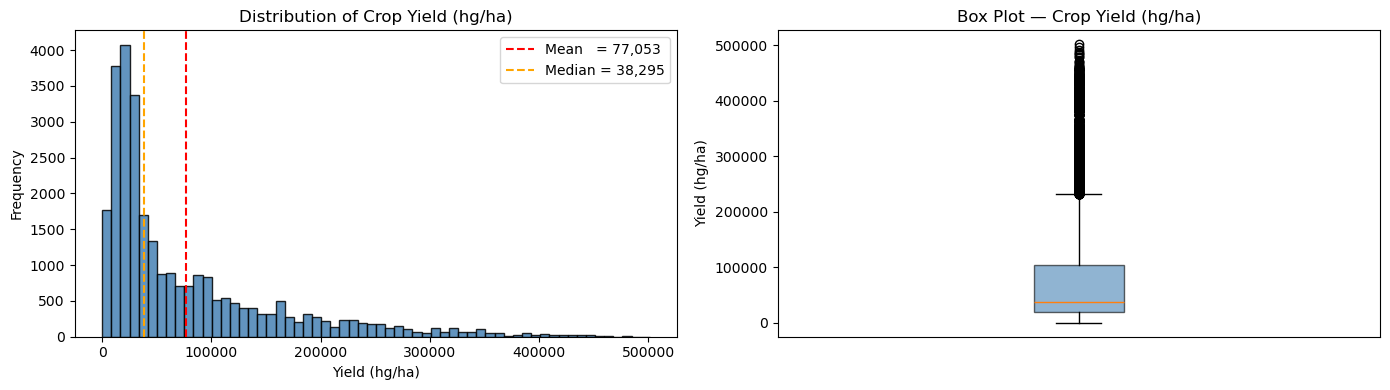

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram
axes[0].hist(data['hg/ha_yield'], bins=60, color='steelblue', edgecolor='black', alpha=0.85)
axes[0].axvline(data['hg/ha_yield'].mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Mean   = {data["hg/ha_yield"].mean():,.0f}')
axes[0].axvline(data['hg/ha_yield'].median(), color='orange', linestyle='--', linewidth=1.5, label=f'Median = {data["hg/ha_yield"].median():,.0f}')
axes[0].set_title('Distribution of Crop Yield (hg/ha)')
axes[0].set_xlabel('Yield (hg/ha)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Box plot
axes[1].boxplot(data['hg/ha_yield'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Box Plot — Crop Yield (hg/ha)')
axes[1].set_ylabel('Yield (hg/ha)')
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

### 6.2 — Average Yield per Crop Type

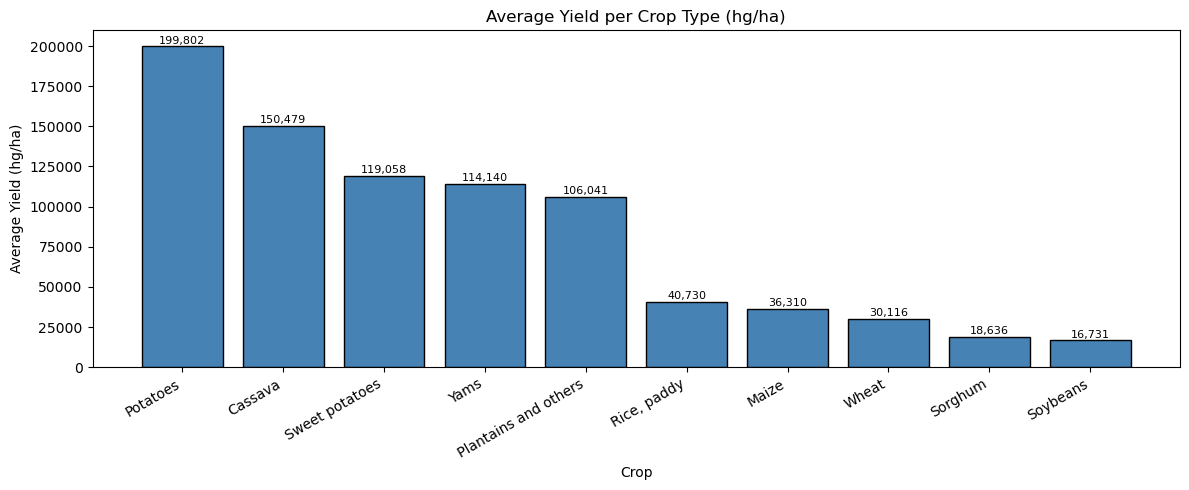

In [10]:
avg_yield_crop = data.groupby('Item')['hg/ha_yield'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(avg_yield_crop.index, avg_yield_crop.values, color='steelblue', edgecolor='black')
for bar, val in zip(bars, avg_yield_crop.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{val:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_title('Average Yield per Crop Type (hg/ha)')
ax.set_xlabel('Crop')
ax.set_ylabel('Average Yield (hg/ha)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 6.3 — Yield Distribution per Crop (Box Plots)

C:\Users\pc\AppData\Local\Temp\ipykernel_4220\3503237271.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(yield_by_crop, labels=crops, patch_artist=True, notch=False)


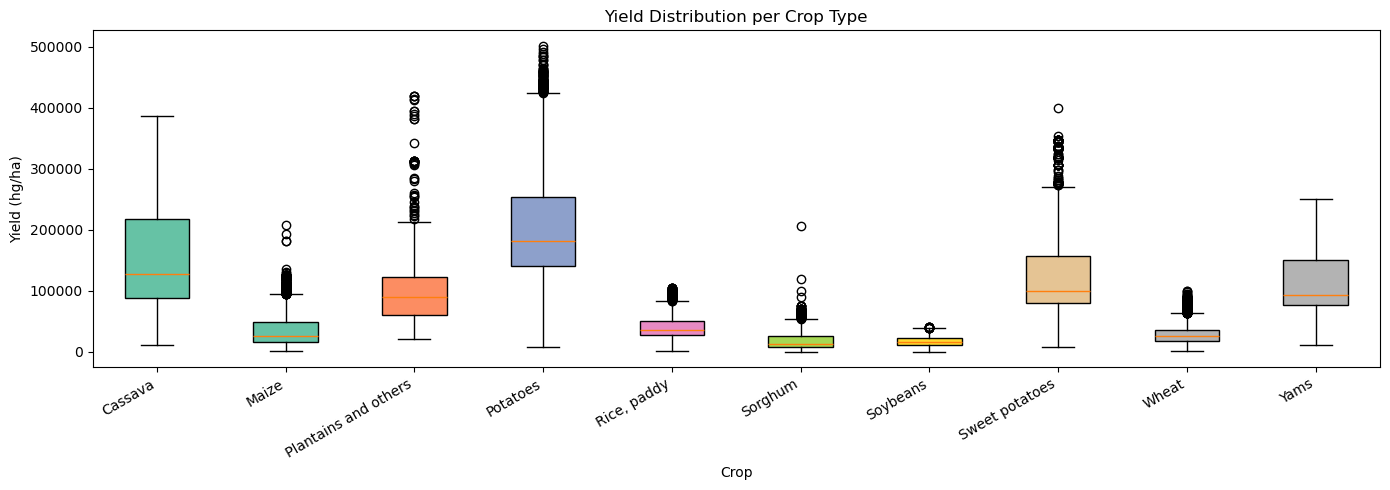

In [11]:
crops = sorted(data['Item'].unique())
yield_by_crop = [data[data['Item'] == c]['hg/ha_yield'].values for c in crops]

fig, ax = plt.subplots(figsize=(14, 5))
bp = ax.boxplot(yield_by_crop, labels=crops, patch_artist=True, notch=False)
colors = plt.cm.Set2(np.linspace(0, 1, len(crops)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax.set_title('Yield Distribution per Crop Type')
ax.set_xlabel('Crop')
ax.set_ylabel('Yield (hg/ha)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 6.4 — Top 20 Countries by Average Yield

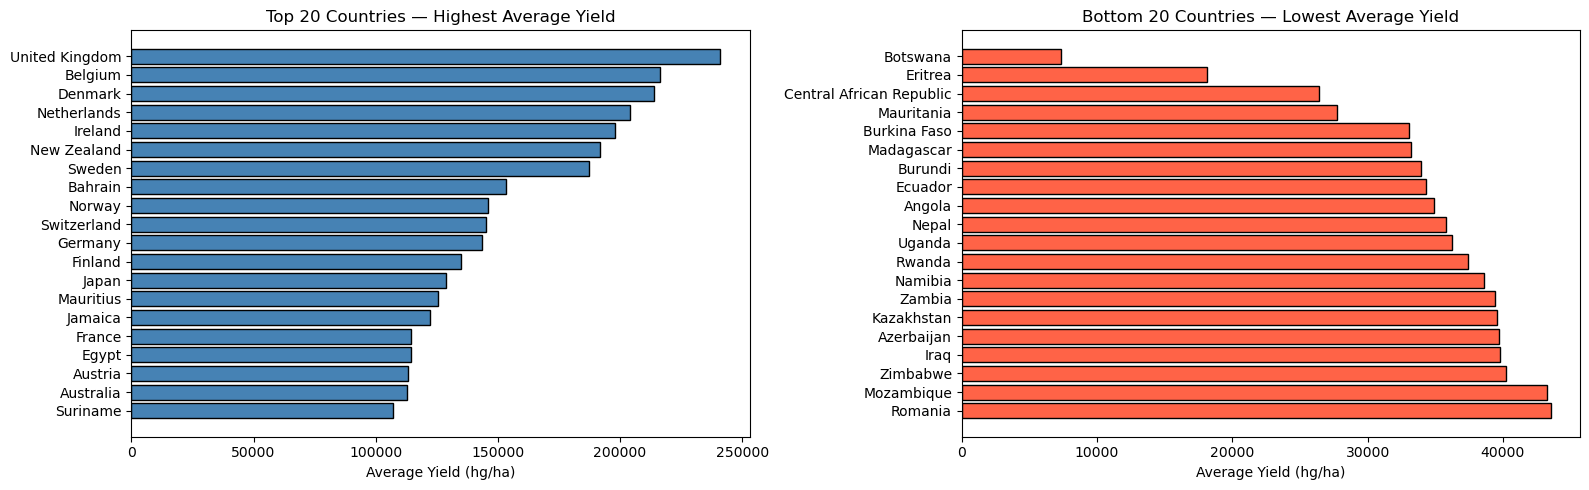

In [12]:
top20 = data.groupby('Area')['hg/ha_yield'].mean().sort_values(ascending=False).head(20)
bot20 = data.groupby('Area')['hg/ha_yield'].mean().sort_values(ascending=True).head(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(top20.index[::-1], top20.values[::-1], color='steelblue', edgecolor='black')
axes[0].set_title('Top 20 Countries — Highest Average Yield')
axes[0].set_xlabel('Average Yield (hg/ha)')

axes[1].barh(bot20.index[::-1], bot20.values[::-1], color='tomato', edgecolor='black')
axes[1].set_title('Bottom 20 Countries — Lowest Average Yield')
axes[1].set_xlabel('Average Yield (hg/ha)')

plt.tight_layout()
plt.show()

### 6.5 — Global Average Yield Trend over Years

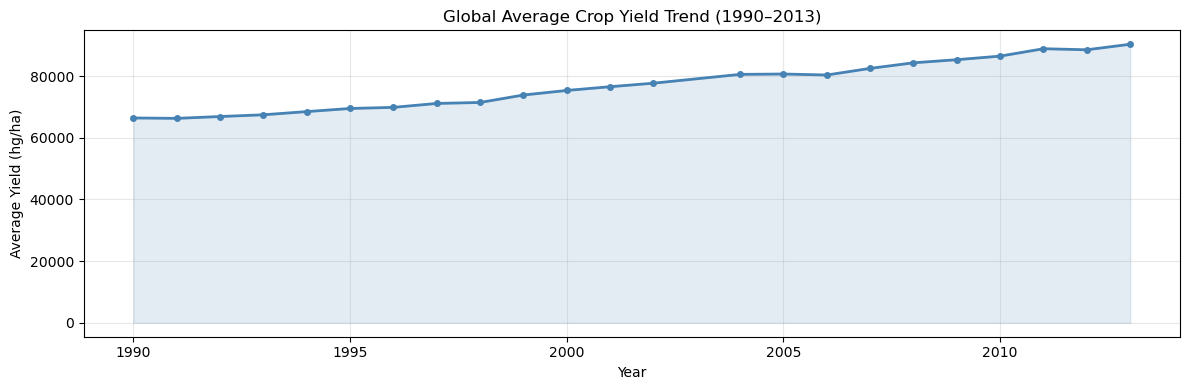

In [13]:
yield_by_year = data.groupby('Year')['hg/ha_yield'].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(yield_by_year.index, yield_by_year.values, color='steelblue', linewidth=2, marker='o', markersize=4)
ax.fill_between(yield_by_year.index, yield_by_year.values, alpha=0.15, color='steelblue')
ax.set_title('Global Average Crop Yield Trend (1990–2013)')
ax.set_xlabel('Year')
ax.set_ylabel('Average Yield (hg/ha)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7 — Feature Analysis

Scatter plots of each numerical feature against the target variable.

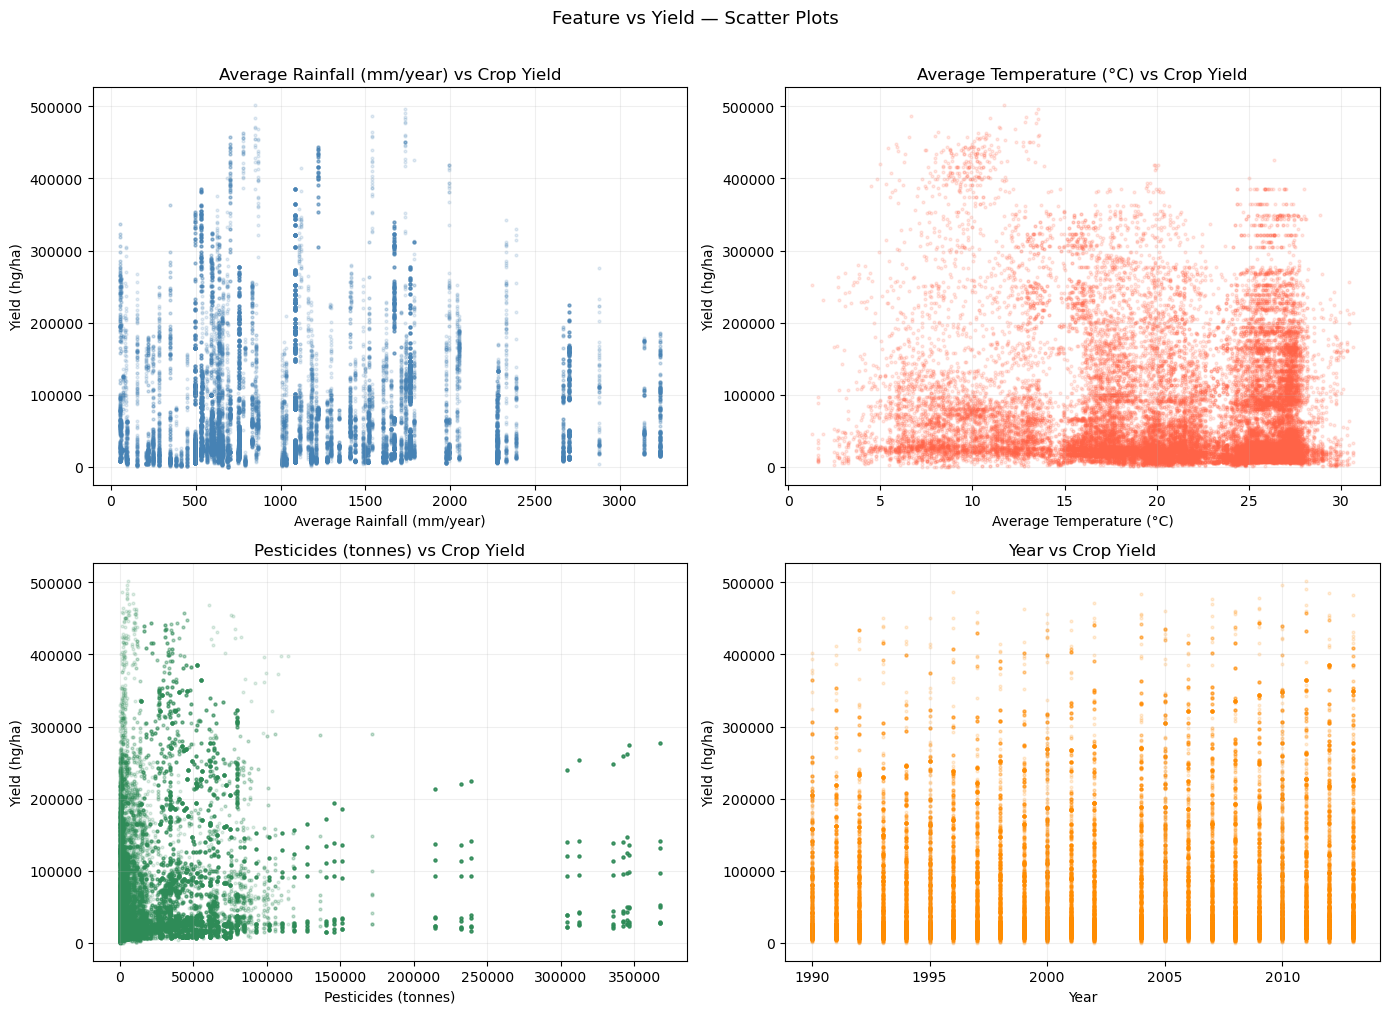

In [14]:
features = [
    ('average_rain_fall_mm_per_year', 'Average Rainfall (mm/year)', 'steelblue'),
    ('avg_temp',                      'Average Temperature (°C)',   'tomato'),
    ('pesticides_tonnes',             'Pesticides (tonnes)',         'seagreen'),
    ('Year',                          'Year',                       'darkorange'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (col, label, color) in zip(axes, features):
    ax.scatter(data[col], data['hg/ha_yield'], alpha=0.15, color=color, s=4)
    ax.set_title(f'{label} vs Crop Yield')
    ax.set_xlabel(label)
    ax.set_ylabel('Yield (hg/ha)')
    ax.grid(True, alpha=0.2)

plt.suptitle('Feature vs Yield — Scatter Plots', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 7.1 — Distribution of Each Numerical Feature

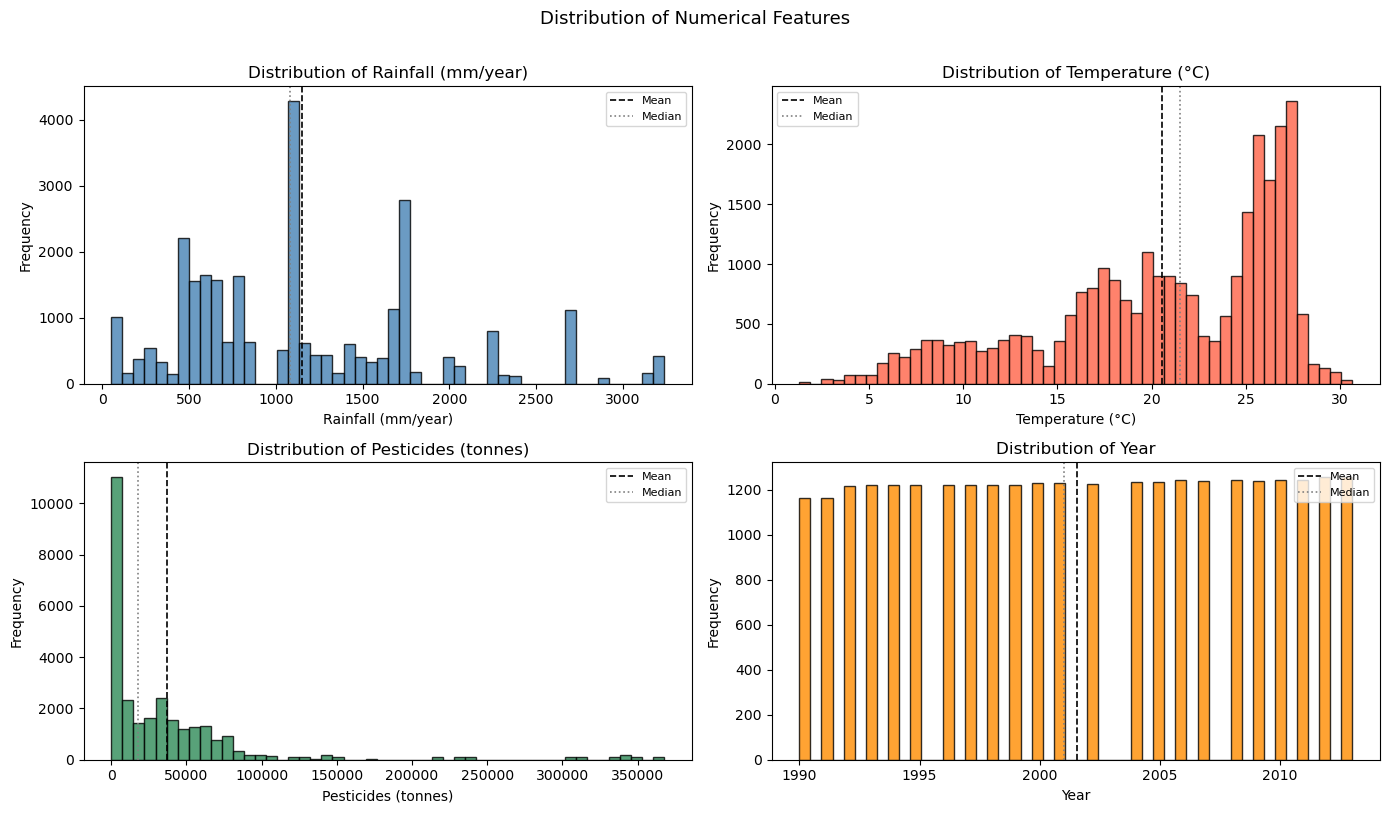

In [15]:
num_cols = ['average_rain_fall_mm_per_year', 'avg_temp', 'pesticides_tonnes', 'Year']
labels   = ['Rainfall (mm/year)', 'Temperature (°C)', 'Pesticides (tonnes)', 'Year']
colors   = ['steelblue', 'tomato', 'seagreen', 'darkorange']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col, label, color in zip(axes, num_cols, labels, colors):
    ax.hist(data[col], bins=50, color=color, edgecolor='black', alpha=0.8)
    ax.axvline(data[col].mean(),   color='black', linestyle='--', linewidth=1.2, label='Mean')
    ax.axvline(data[col].median(), color='grey',  linestyle=':',  linewidth=1.2, label='Median')
    ax.set_title(f'Distribution of {label}')
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)

plt.suptitle('Distribution of Numerical Features', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 8 — Correlation Analysis

In [16]:
num_all = ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'hg/ha_yield']
corr    = data[num_all].corr()

print('Correlation with hg/ha_yield (sorted):')
print(corr['hg/ha_yield'].sort_values(ascending=False).round(4))

Correlation with hg/ha_yield (sorted):
hg/ha_yield                      1.0000
Year                             0.0916
pesticides_tonnes                0.0641
average_rain_fall_mm_per_year    0.0010
avg_temp                        -0.1148
Name: hg/ha_yield, dtype: float64


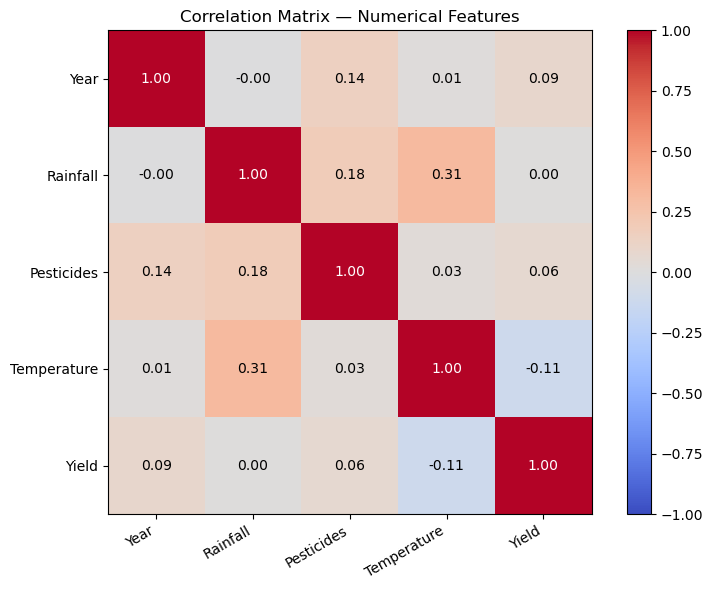

In [17]:
col_labels = ['Year', 'Rainfall', 'Pesticides', 'Temperature', 'Yield']

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(col_labels)))
ax.set_yticks(range(len(col_labels)))
ax.set_xticklabels(col_labels, rotation=30, ha='right')
ax.set_yticklabels(col_labels)
for i in range(len(col_labels)):
    for j in range(len(col_labels)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=10,
                color='white' if abs(corr.values[i, j]) > 0.5 else 'black')
ax.set_title('Correlation Matrix — Numerical Features', fontsize=12)
plt.tight_layout()
plt.show()

## 9 — Observations and Conclusions

**Dataset summary:**
- 28,242 records — 101 countries — 10 crops — years 1990 to 2013
- No missing values → no imputation needed
- 2 categorical features: **Area** and **Item** → require OneHotEncoding
- 4 numerical features: **Year**, **average_rain_fall_mm_per_year**, **pesticides_tonnes**, **avg_temp** → require StandardScaler
- Target: **hg/ha_yield** is continuous → confirmed **Regression problem**

**Key observations:**
- Yield varies enormously across crops and countries
- Global average yield shows an **upward trend** from 1990 to 2013
- Pesticide usage has the strongest positive correlation with yield
- Temperature and rainfall have a **non-linear** influence → linear models will underperform
- Sugar cane and cassava produce the highest average yields; soybeans and sorghum the lowest
- Non-linear models (Random Forest, Gradient Boosting) are expected to outperform Linear Regression